# A simplified event count: one energy, a pure beam, one formula

The full predictions (`fd_spectra_quickstart.ipynb`) integrate flux × cross section × probability over energy,
with detector response and backgrounds. Here everything is reduced to **one formula per experiment and beam mode**,
so that every factor and its unit is visible, while keeping the totals close to what the experiments expect.

1. The formula and its units
2. The assumptions
3. The ingredients: exposure, cross sections, flux and beam energy (all from public, citable sources)
4. Number of events and the effective efficiency
5. Bi-probability and bi-event plots
6. $\delta_{CP}$ sensitivity for the two orderings

## 1. The formula

For an appearance measurement with a $\nu_\mu$ ($\bar\nu_\mu$) beam, the number of $\nu_e$ ($\bar\nu_e$) charged-current
events selected in the far detector is

$$
\boxed{\;N = \varepsilon_\text{eff} \;\times\; P(\nu_\mu\to\nu_e;\,E_0, L) \;\times\; \sigma_{CC}(E_0) \;\times\; \Phi \;\times\; \mathrm{POT} \;\times\; N_T\;}
$$

| symbol | meaning | unit |
|---|---|---|
| $\Phi$ | $\nu_\mu$ ($\bar\nu_\mu$) flux at the far detector, integrated over energy, per proton on target | $\nu\ \mathrm{cm^{-2}\ POT^{-1}}$ |
| $\mathrm{POT}$ | protons on target delivered in that beam mode (the exposure) | POT |
| $N_T = M\,N_A / (1\ \mathrm{g})$ | target nucleons in a detector of mass $M$ (one nucleon per atomic mass unit) | nucleons |
| $\sigma_{CC}(E_0)$ | inclusive $\nu_e$ ($\bar\nu_e$) CC cross section per nucleon at the beam energy $E_0$ | $\mathrm{cm^2}$ |
| $P$ | oscillation probability at $E_0$ and baseline $L$ | – |
| $\varepsilon_\text{eff}$ | effective efficiency (section 4) | – |

Units: $[\mathrm{cm^{-2}\,POT^{-1}}]\times[\mathrm{POT}]\times[\mathrm{cm^2}]\times[\text{nucleons}]$ = number of events.

Pocket version, with each factor in its natural unit:

$$
N \simeq 60.2 \times \varepsilon_\text{eff}\, P \times \frac{\sigma_{CC}}{10^{-38}\,\mathrm{cm^2}} \times \frac{\Phi}{10^{-14}\,\mathrm{cm^{-2}POT^{-1}}}
\times \frac{\mathrm{POT}}{10^{21}} \times \frac{M}{1\,\mathrm{kt}},
\qquad 10^{-38}\cdot10^{-14}\cdot10^{21}\cdot(10^{9}\,\mathrm{g}\cdot N_A) = 60.2 .
$$

With $P=1$ and $\varepsilon_\text{eff}=1$ the formula gives the number of CC interactions there would be if every
$\nu_\mu$ became a $\nu_e$.

## 2. Assumptions

1. **Pure beam.** The $\nu$ beam contains only $\nu_\mu$, the $\bar\nu$ beam only $\bar\nu_\mu$: no wrong-sign component
   (5–10 % of the flux) and no intrinsic $\nu_e$ (~1 %). Only the "right-sign" appearance signal is counted.
2. **One energy.** All neutrinos have the same energy $E_0$, the flux-weighted **mean energy of the main peak of the beam**
   (energy bins where the flux is above 10 % of its maximum, which removes the long high-energy tail):
   $E_0\approx 0.57$ GeV for T2K/Hyper-K, 1.8 GeV for NOvA, 2.3 GeV for DUNE.
3. **Total flux.** $\Phi$ is the whole $\nu_\mu$ ($\bar\nu_\mu$) flux at the far detector from the public flux releases
   (`fluxes/`, see `fluxes/README.md`; NOvA: near-detector flux × $(1\,\mathrm{km}/810\,\mathrm{km})^2$).
4. **One cross section**, the inclusive CC cross section per nucleon at $E_0$, from the same public table that is used
   in each experiment's public GLoBES configuration:
   * T2K, Hyper-K, NOvA: the GLoBES standard `XCC.dat` (low energy from the Super-Kamiokande cross sections for water,
     Messier 1999; high energy from Paschos & Yu, PRD 65, 033002 (2002));
   * DUNE: the GENIE cross sections on argon of the DUNE TDR configuration (arXiv:2103.04797).
5. **Targets.** $N_T = M N_A$ (nucleons per gram), $M$ = fiducial mass (total mass for NOvA).
6. **Effective efficiency.** One number per experiment and beam mode, $\varepsilon_\text{eff}$, fixed so that the formula
   reproduces the expected number of signal events of the full simulation (section 4). It absorbs the detector
   efficiency *and* the error of the approximations 1–4.
7. **No backgrounds, no energy resolution, no systematics** (except one normalisation uncertainty in the sensitivity),
   constant matter density, oscillation parameters at NuFIT 6.0 (arXiv:2410.05380).

In [25]:
import numpy as np
import matplotlib.pyplot as plt

from nuosc import NeutrinoOscillator, get_experiment, load_flux, predict
from nuosc.paths import ROOT
from nuosc.plotting import set_style

SET_STYLE = True     # True: nuosc style (latex_style -> SciencePlots -> default); False: keep your own matplotlib settings
c = set_style(SET_STYLE)

EXPERIMENTS = ["T2K", "HyperK", "NOvA", "DUNE"]
MODES = {"FHC": False, "RHC": True}        # beam mode -> antineutrino?
N_A = 6.02214076e23                        # nucleons per gram (1 / atomic mass unit)

plot style: latex_style


## 3. The ingredients

### Exposure and detector

Same numbers as in `far_detector_spectra/`: T2K Run 1–9 (arXiv:2101.03779) and NOvA 2024 analysis (current);
Hyper-K Design Report, 10 yr at 1.3 MW (arXiv:1805.04163) and DUNE TDR, 6.5 + 6.5 yr at 1.2 MW (arXiv:2103.04797)
(projected).

In [26]:
SETUP = {
    #             flux file   mass [kt]   POT in the nu beam / nubar beam             cross section  exposure
    "T2K":    dict(flux="T2K",  M_kt=22.5,  POT={"FHC": 14.94e20, "RHC": 16.35e20}, xs="GLoBES", status="current: Run 1-9"),
    "HyperK": dict(flux="T2K",  M_kt=187.0, POT={"FHC": 0.675e22, "RHC": 2.025e22}, xs="GLoBES", status="projected: 10 yr, 1.3 MW"),
    "NOvA":   dict(flux="NOvA", M_kt=14.0,  POT={"FHC": 26.61e20, "RHC": 12.5e20},  xs="GLoBES", status="current: 2024 analysis"),
    "DUNE":   dict(flux="DUNE", M_kt=40.0,  POT={"FHC": 7.15e21,  "RHC": 7.15e21},  xs="GENIE-Ar", status="projected: 6.5+6.5 yr, 1.2 MW"),
}

### Cross sections

Two public tables, both giving $\sigma/E$ per nucleon in $10^{-38}\,\mathrm{cm^2/GeV}$ as a function of $\log_{10}(E/\mathrm{GeV})$
for $\nu_e,\nu_\mu,\nu_\tau,\bar\nu_e,\bar\nu_\mu,\bar\nu_\tau$:

| table | file | target | references |
|---|---|---|---|
| **GLoBES** standard (`XCC.dat`, also `XQE.dat` for the quasi-elastic part) | `data/GLoBES_xsec/` | water at low energy (Super-K), isoscalar at high energy | M. D. Messier, PhD thesis, Boston Univ. (1999); E. A. Paschos, J. Y. Yu, PRD 65, 033002 (2002); GLoBES: P. Huber *et al.*, CPC 167, 195 (2005), CPC 177, 432 (2007) |
| **GENIE** 2.12 on argon | `data/DUNE_GLoBES_2103.04797/dune_globes/xsec/` | argon | DUNE Collaboration, arXiv:2103.04797; C. Andreopoulos *et al.*, NIM A 614, 87 (2010) |

The GENIE table is a Monte Carlo histogram and is noisy below ~1 GeV, so it is smoothed with a 7-point running mean in
$\log E$ (the same smoothing used to build `far_detector_spectra/`).

In [27]:
XCOL = {"nue": 1, "numu": 2, "nuebar": 4, "numubar": 5}

def load_xs(path, smooth=False):
    t = np.loadtxt(path)                      # comment lines (#) are skipped
    if smooth:
        k = np.ones(7) / 7
        for j in range(1, t.shape[1]):
            t[:, j] = np.convolve(np.pad(t[:, j], 3, mode="edge"), k, mode="valid")
    return t

XS = {
    "GLoBES":    load_xs(ROOT / "data" / "GLoBES_xsec" / "XCC.dat"),
    "GLoBES-QE": load_xs(ROOT / "data" / "GLoBES_xsec" / "XQE.dat"),
    "GENIE-Ar":  load_xs(ROOT / "data" / "DUNE_GLoBES_2103.04797" / "dune_globes" / "xsec" / "xsec_cc.dat", smooth=True),
}

def sigma_cc(E, flavour, table="GLoBES"):
    # cross section per nucleon [cm^2] at energy E [GeV]
    t = XS[table]
    return np.interp(np.log10(E), t[:, 0], t[:, XCOL[flavour]]) * E * 1e-38

for E in [0.6, 1.8, 2.3]:
    print(f"E = {E} GeV:  sigma(nu_e) GLoBES {sigma_cc(E, 'nue'):.2e}, GENIE-Ar {sigma_cc(E, 'nue', 'GENIE-Ar'):.2e} cm^2;"
          f"  sigma(nubar_e) GLoBES {sigma_cc(E, 'nuebar'):.2e}, GENIE-Ar {sigma_cc(E, 'nuebar', 'GENIE-Ar'):.2e} cm^2")

E = 0.6 GeV:  sigma(nu_e) GLoBES 4.38e-39, GENIE-Ar 5.08e-39 cm^2;  sigma(nubar_e) GLoBES 1.32e-39, GENIE-Ar 1.17e-39 cm^2
E = 1.8 GeV:  sigma(nu_e) GLoBES 1.44e-38, GENIE-Ar 1.51e-38 cm^2;  sigma(nubar_e) GLoBES 6.35e-39, GENIE-Ar 5.72e-39 cm^2
E = 2.3 GeV:  sigma(nu_e) GLoBES 1.84e-38, GENIE-Ar 1.78e-38 cm^2;  sigma(nubar_e) GLoBES 8.56e-39, GENIE-Ar 7.40e-39 cm^2


**Plots.** Left: $\sigma/E$. At high energy (deep-inelastic scattering, tens of GeV and above) $\sigma/E$ tends to a
constant, $\approx 0.67$ for $\nu$ and $0.34\times10^{-38}\,\mathrm{cm^2/GeV}$ for $\bar\nu$ (dotted lines): the cross section
grows linearly with energy. Below ~1 GeV quasi-elastic scattering ($\nu_\ell n\to\ell^- p$, $\bar\nu_\ell p\to\ell^+ n$, dash-dotted:
GLoBES `XQE.dat`) dominates and $\sigma/E$ falls. Right: $\sigma$ itself. Vertical lines: the beam energies $E_0$.

At the beam energies used here the two tables differ by up to ~15 % for $\nu$ and ~20 % for $\bar\nu$ (different
nuclei, oxygen vs argon, and different models); this difference is absorbed by $\varepsilon_\text{eff}$ in section 4. The $\bar\nu$ cross section is 2–4 times smaller than the $\nu$ one: this is why the $\bar\nu$ beam needs more
POT for the same number of events.

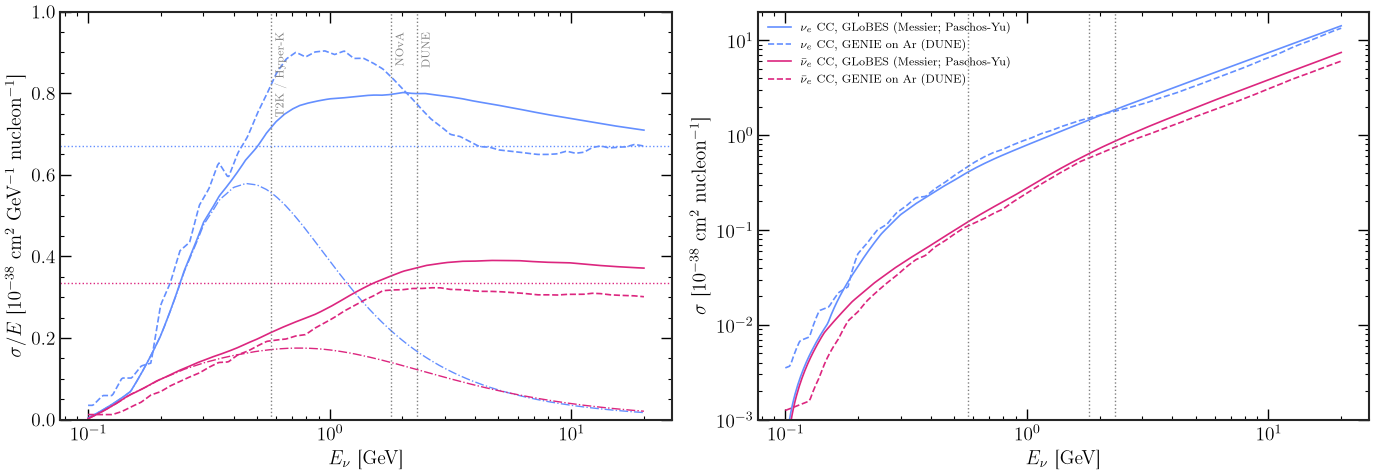

In [28]:
E = np.logspace(-1, np.log10(20), 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for i, (fl, lab) in enumerate((("nue", r"$\nu_e$"), ("nuebar", r"$\bar\nu_e$"))):
    for table, ls, name in (("GLoBES", "-", "GLoBES (Messier; Paschos-Yu)"), ("GENIE-Ar", "--", "GENIE on Ar (DUNE)")):
        ax1.plot(E, sigma_cc(E, fl, table) / E / 1e-38, color=c[i], ls=ls, label=f"{lab} CC, {name}")
        ax2.plot(E, sigma_cc(E, fl, table) / 1e-38, color=c[i], ls=ls, label=f"{lab} CC, {name}")
    ax1.plot(E, sigma_cc(E, fl, "GLoBES-QE") / E / 1e-38, color=c[i], ls="-.", lw=1, label=f"{lab} quasi-elastic (GLoBES)")
ax1.axhline(0.67, color=c[0], ls=":", lw=1)
ax1.axhline(0.335, color=c[1], ls=":", lw=1)
for lab, e0 in {"T2K / Hyper-K": 0.57, "NOvA": 1.80, "DUNE": 2.31}.items():
    for ax in (ax1, ax2):
        ax.axvline(e0, color="gray", ls=":", lw=1)
    ax1.text(e0 * 1.04, 0.95, lab, fontsize="x-small", color="gray", rotation=90, va="top")
ax1.set_ylabel(r"$\sigma/E$ [$10^{-38}$ cm$^2$ GeV$^{-1}$ nucleon$^{-1}$]")
ax2.set_ylabel(r"$\sigma$ [$10^{-38}$ cm$^2$ nucleon$^{-1}$]")
for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.set_xlabel(r"$E_\nu$ [GeV]")
ax1.set_ylim(0, 1.0)
ax2.set_yscale("log")
ax2.set_ylim(1e-3, 20)
ax2.legend(fontsize="x-small", loc="upper left")
plt.tight_layout()
plt.show()

### Flux and mean energy

From the public flux files: $\Phi = \int \frac{d\Phi}{dE}\,dE$ and $E_0$ = flux-weighted mean energy of the main peak.
For comparison, `<E> all` is the mean over the whole spectrum, pulled up by the high-energy tail.

In [29]:
def flux_summary(flux_name, mode):
    flav = "numu" if mode == "FHC" else "numubar"
    f = load_flux(flux_name, mode)
    e, v = f.edges[flav], f.values[flav]                 # dPhi/dE [nu / cm^2 / GeV / POT]
    Ec, dE = 0.5 * (e[1:] + e[:-1]), np.diff(e)
    Phi = np.sum(v * dE)                                 # total flux [nu / cm^2 / POT]
    peak = v > 0.1 * v.max()                             # main peak of the beam
    E0 = np.sum((v * dE * Ec)[peak]) / np.sum((v * dE)[peak])
    E_mean_all = np.sum(v * dE * Ec) / Phi
    return Phi, E0, E_mean_all

ING = {}
print(f"{'':7s} {'beam':4s} {'Phi [cm^-2 POT^-1]':>19s} {'E0 [GeV]':>9s} {'<E> all':>8s} {'sigma(E0) [cm^2]':>17s} {'table':>9s} {'N_T':>9s}")
for name in EXPERIMENTS:
    s = SETUP[name]
    for m, anti in MODES.items():
        Phi, E0, Eall = flux_summary(s["flux"], m)
        sig = sigma_cc(E0, "nuebar" if anti else "nue", s["xs"])
        NT = s["M_kt"] * 1e9 * N_A
        ING[(name, m)] = dict(Phi=Phi, E0=E0, sigma=sig, NT=NT, POT=s["POT"][m], eps=1.0)
        print(f"{name:7s} {m:4s} {Phi:19.3e} {E0:9.2f} {Eall:8.2f} {sig:17.2e} {s['xs']:>9s} {NT:9.2e}")

        beam  Phi [cm^-2 POT^-1]  E0 [GeV]  <E> all  sigma(E0) [cm^2]     table       N_T
T2K     FHC            1.207e-14      0.57     0.82          4.07e-39    GLoBES  1.35e+34
T2K     RHC            9.763e-15      0.55     0.68          1.16e-39    GLoBES  1.35e+34
HyperK  FHC            1.207e-14      0.57     0.82          4.07e-39    GLoBES  1.13e+35
HyperK  RHC            9.763e-15      0.55     0.68          1.16e-39    GLoBES  1.13e+35
NOvA    FHC            1.806e-14      1.80     2.59          1.43e-38    GLoBES  8.43e+33
NOvA    RHC            1.467e-14      1.79     2.29          6.31e-39    GLoBES  8.43e+33
DUNE    FHC            1.548e-14      2.31     2.88          1.78e-38  GENIE-Ar  2.41e+34
DUNE    RHC            1.385e-14      2.27     2.59          7.29e-39  GENIE-Ar  2.41e+34


## 4. Number of events and the effective efficiency

### 4a. The formula with $\varepsilon_\text{eff} = 1$

$N_{P=1} = \Phi\,\mathrm{POT}\,N_T\,\sigma$ is the number of CC interactions if every $\nu_\mu$ became a $\nu_e$, and
$N_{\varepsilon=1} = P\,N_{P=1}$ the oscillated number before any selection.

In [30]:
def n_events(name, mode, osc=None, ordering="NO", delta_cp=None):
    # simplified number of selected nu_mu -> nu_e (FHC) or nubar_mu -> nubar_e (RHC) events
    g = ING[(name, mode)]
    if osc is None:
        kw = {} if delta_cp is None else dict(delta_cp=delta_cp)
        osc = NeutrinoOscillator.from_experiment(name, ordering=ordering, antineutrino=MODES[mode], **kw)
    P = float(osc.matter("mu", "e", E=g["E0"]))
    return g["eps"] * P * g["sigma"] * g["Phi"] * g["POT"] * g["NT"]

g = ING[("T2K", "FHC")]
N_P1 = 60.2 * (g["sigma"] / 1e-38) * (g["Phi"] / 1e-14) * (g["POT"] / 1e21) * SETUP["T2K"]["M_kt"]
print(f"practical formula, T2K nu beam: N(P=1) = 60.2 x {g['sigma'] / 1e-38:.3f} x {g['Phi'] / 1e-14:.3f} x "
      f"{g['POT'] / 1e21:.3f} x {SETUP['T2K']['M_kt']} = {N_P1:.0f}\n")

print(f"{'':7s} {'beam':4s} {'N(P=1)':>9s} {'P(E0)':>7s} {'N(eps=1)':>9s}")
for name in EXPERIMENTS:
    for m, anti in MODES.items():
        g = ING[(name, m)]
        N1 = g["sigma"] * g["Phi"] * g["POT"] * g["NT"]
        P = float(NeutrinoOscillator.from_experiment(name, antineutrino=anti).matter("mu", "e", E=g["E0"]))
        print(f"{name:7s} {m:4s} {N1:9.0f} {P:7.4f} {n_events(name, m):9.1f}")

practical formula, T2K nu beam: N(P=1) = 60.2 x 0.407 x 1.207 x 1.494 x 22.5 = 994

        beam    N(P=1)   P(E0)  N(eps=1)
T2K     FHC        994  0.0533      53.0
T2K     RHC        250  0.0316       7.9
HyperK  FHC      37336  0.0533    1990.5
HyperK  RHC      25773  0.0316     813.7
NOvA    FHC       5811  0.0547     317.7
NOvA    RHC        975  0.0249      24.3
DUNE    FHC      47547  0.0738    3509.6
DUNE    RHC      17380  0.0178     310.1


### 4b. Calibration: the expected number of events

The reference is the appearance signal of the full simulation in `far_detector_spectra/` (flux × cross section ×
probability integrated over energy, with the detector response), which reproduces the numbers published by each
collaboration: T2K Table XI of arXiv:2101.03779, NOvA Table 2 of arXiv:2509.04361, Hyper-K Tables XXXVI–XXXVII of the
Design Report arXiv:1805.04163, DUNE TDR configuration arXiv:2103.04797 (see `fd_spectra_quickstart.ipynb`).
It is evaluated with the same NuFIT 6.0 NO parameters.

$$
\varepsilon_\text{eff} = \frac{N_\text{expected}}{N_{\varepsilon=1}}\quad\text{(rounded to 0.05)} .
$$

In [31]:
print(f"{'':7s} {'beam':4s} {'N(eps=1)':>9s} {'N expected':>11s} {'eps_eff':>8s} {'N simple':>9s}")
for name in EXPERIMENTS:
    full = predict(name, NeutrinoOscillator("NO"))
    for m, anti in MODES.items():
        g = ING[(name, m)]
        g["eps"] = 1.0
        N_eps1 = n_events(name, m)
        N_exp = full[m]["numubar_e" if anti else "numu_e"].sum()
        g["eps"] = round(N_exp / N_eps1 / 0.05) * 0.05            # effective efficiency
        print(f"{name:7s} {m:4s} {N_eps1:9.1f} {N_exp:11.1f} {g['eps']:8.2f} {n_events(name, m):9.1f}")

        beam  N(eps=1)  N expected  eps_eff  N simple
T2K     FHC       53.0        51.0     0.95      50.4
T2K     RHC        7.9         9.1     1.15       9.1
HyperK  FHC     1990.5      1502.2     0.75    1492.8
HyperK  RHC      813.7       784.5     0.95     773.0
NOvA    FHC      317.7       134.6     0.40     127.1
NOvA    RHC       24.3        12.5     0.50      12.1
DUNE    FHC     3509.6      2034.1     0.60    2105.7
DUNE    RHC      310.1       262.4     0.85     263.6


### 4c. What is inside $\varepsilon_\text{eff}$? Are these numbers realistic?

$\varepsilon_\text{eff}$ is the product of two factors:

$$
\varepsilon_\text{eff} = \frac{N_\text{expected}}{N_{\varepsilon=1}} =
\underbrace{\frac{N_\text{expected}}{\mathrm{POT}\,N_T\int\Phi(E)\,\sigma(E)\,P(E)\,dE}}_{\varepsilon_\text{det}\ \text{(selection)}}
\times
\underbrace{\frac{\int\Phi(E)\,\sigma(E)\,P(E)\,dE}{\Phi\,\sigma(E_0)\,P(E_0)}}_{c_\text{mono}\ \text{(one-energy correction)}} .
$$

* $\varepsilon_\text{det}$: fraction of the oscillated signal interactions that end up in the selected sample;
* $c_\text{mono}$: how much the one-energy formula over- or under-estimates the energy integral.

In [32]:
from nuosc.formulas import prob_matter_nufast

Egrid = np.linspace(0.05, 20, 40000)
dEg = Egrid[1] - Egrid[0]
osc_no = NeutrinoOscillator("NO")
print(f"{'':7s} {'beam':4s} {'eps_det':>8s} {'c_mono':>7s} {'eps_eff':>8s}")
for name in EXPERIMENTS:
    cfg, s = get_experiment(name), SETUP[name]
    full = predict(name, osc_no)
    for m, anti in MODES.items():
        g = ING[(name, m)]
        f = load_flux(s["flux"], m)
        f.interpolate = False
        phi = f("numubar" if anti else "numu", Egrid)
        sig = sigma_cc(Egrid, "nuebar" if anti else "nue", s["xs"])
        P = prob_matter_nufast(Egrid, cfg["baseline"], **osc_no.params, rho=cfg["rho"], antineutrino=anti)[1, 0]
        N_int = np.sum(phi * sig * P) * dEg * g["POT"] * g["NT"]     # oscillated interactions, full energy integral
        N_mono = n_events(name, m) / g["eps"]                       # one-energy formula, eps = 1
        N_exp = full[m]["numubar_e" if anti else "numu_e"].sum()
        print(f"{name:7s} {m:4s} {N_exp / N_int:8.2f} {N_int / N_mono:7.2f} {g['eps']:8.2f}")

        beam  eps_det  c_mono  eps_eff
T2K     FHC      1.22    0.79     0.95
T2K     RHC      1.24    0.93     1.15
HyperK  FHC      0.96    0.79     0.75
HyperK  RHC      1.04    0.93     0.95
NOvA    FHC      0.55    0.77     0.40
NOvA    RHC      0.61    0.85     0.50
DUNE    FHC      0.86    0.68     0.60
DUNE    RHC      0.94    0.90     0.85


**Reading the table**

* **$c_\text{mono} < 1$ everywhere:** putting every neutrino at $E_0$ overestimates the signal, because $E_0$ is close to
  the oscillation maximum while the real flux is spread over energies where $P$ is smaller. Part of $\varepsilon_\text{eff}$
  is therefore *not* a detector effect.
* **DUNE:** $\varepsilon_\text{det}$ comes directly from the official detector response of the DUNE configuration
  (post-smearing efficiencies and analysis energy window, arXiv:2103.04797), not from a fit: it is a genuine
  selection efficiency.
* **T2K, Hyper-K, NOvA:** no public detector response exists, so in `far_detector_spectra/` the efficiencies were
  calibrated to the published event totals. Here $\varepsilon_\text{det}$ is the ratio between those totals and our
  flux × cross-section integral: it also contains any difference between our cross-section table and the one used by
  the collaborations, the fiducial-volume cut (NOvA: we use the total mass), and, for T2K, the near-detector
  constraint on the flux. It should be read as an *effective* efficiency.
* **$\nu$ vs $\bar\nu$ beam:** the efficiencies differ between beam modes mostly because of the cross section at low
  energy (for water, free protons in hydrogen contribute to $\bar\nu$ quasi-elastic scattering) and because the
  $\bar\nu$ flux has a different energy spread.

In a thesis: $\varepsilon_\text{eff}$ is a **normalisation** fixed to the expected numbers of events of the
collaborations (references above); the formula then explains how the number of events scales with exposure, mass,
cross section and oscillation probability.

## 5. Bi-probability and bi-event plots

Varying $\delta_{CP}$ from 0 to $360°$ (other parameters at the NuFIT 6.0 best fit of each ordering).
**Top:** probabilities at $E_0$ of the $\nu$ and $\bar\nu$ beam. **Bottom:** the same in number of events: in the
simplified model the events are just the probabilities times a constant ($\varepsilon_\text{eff} N_{P=1}$), so the shapes are identical.

Circles: $\delta_{CP}=0$; squares: $90°$; stars: the current global best fit (NuFIT 6.0, $212°$ NO, $274°$ IO)
with the statistical error $\sqrt N$ of each experiment's exposure (current for T2K and NOvA, projected for Hyper-K and DUNE).

**Best-fit points.** Two versions of the same plot:

* **(a) global fit:** all experiments at the NuFIT 6.0 best fit of each ordering (arXiv:2410.05380):
  $\delta_{CP} = 212°$ (NO), $274°$ (IO);
* **(b) each experiment's own latest result** for T2K and NOvA (current), NuFIT 6.0 for Hyper-K and DUNE (projected):

| | NO: $\delta_{CP}$, $\sin^2\theta_{23}$, $\Delta m^2_{32}$ [$10^{-3}$ eV²] | IO: $\delta_{CP}$, $\sin^2\theta_{23}$, $\Delta m^2_{32}$ | $\theta_{13}$ | reference |
|---|---|---|---|---|
| T2K | $-2.18$ rad ($235°$), 0.559, $+2.506$ | $-1.37$ rad ($281°$); $\theta_{23}$, $\Delta m^2_{32}$ not quoted → NuFIT IO | $\sin^2\theta_{13} = 0.0221$ (reactor constraint) | arXiv:2506.05889 (frequentist, reactor constraint) |
| NOvA | $0.87\pi$ ($157°$), 0.547, $+2.441$ | $1.53\pi$ ($275°$), 0.541, $-2.481$ | $\sin^22\theta_{13} = 0.0851$ (Daya Bay) | arXiv:2509.04361 (frequentist, Daya Bay 1D constraint) |

The other parameters ($\theta_{12}$, $\Delta m^2_{21}$) are NuFIT 6.0. In each panel the ellipses are drawn with the same
parameters as the best-fit point, varying only $\delta_{CP}$, so the star always lies on its ellipse.

In [33]:
# latest best fits of the experiments (frequentist); missing values -> NuFIT 6.0 of that ordering
BF_EXP = {
    "T2K":  {"NO": dict(delta_cp=np.degrees(-2.18) % 360, s2_23=0.559, dm2_32=+2.506e-3, s2_13=0.0221),
             "IO": dict(delta_cp=np.degrees(-1.37) % 360, s2_13=0.0221)},
    "NOvA": {"NO": dict(delta_cp=0.87 * 180, s2_23=0.547, dm2_32=+2.441e-3, s2_13=(1 - np.sqrt(1 - 0.0851)) / 2),
             "IO": dict(delta_cp=1.53 * 180, s2_23=0.541, dm2_32=-2.481e-3, s2_13=(1 - np.sqrt(1 - 0.0851)) / 2)},
}
BF_LABEL = {"T2K": "T2K 2025", "NOvA": "NOvA 2025"}

def make_osc(name, o, anti, source, delta=None):
    # oscillator with the best-fit parameters of `source` ("nufit" or "experiments"), optionally another delta_CP
    p = dict(BF_EXP[name][o]) if (source == "experiments" and name in BF_EXP) else {}
    if delta is not None:
        p["delta_cp"] = delta
    return NeutrinoOscillator.from_experiment(name, ordering=o, antineutrino=anti, **p)

def bi_plot(source):
    deltas = np.arange(0, 361, 5)
    fig, axes = plt.subplots(2, 4, figsize=(20, 9))
    for j, name in enumerate(EXPERIMENTS):
        who = BF_LABEL[name] if (source == "experiments" and name in BF_EXP) else "NuFIT 6.0"
        for i, o in enumerate(("NO", "IO")):
            P, N = [], []
            for d in deltas:
                oscs = [make_osc(name, o, anti, source, delta=d) for anti in MODES.values()]
                P.append([float(osc.matter("mu", "e", E=ING[(name, m)]["E0"])) for osc, m in zip(oscs, MODES)])
                N.append([n_events(name, m, osc) for osc, m in zip(oscs, MODES)])
            P, N = np.array(P), np.array(N)
            for row, Z in ((0, P), (1, N)):
                ax = axes[row, j]
                ax.plot(Z[:, 0], Z[:, 1], color=c[i], label=o)
                ax.plot(*Z[0], "o", color=c[i])
                ax.plot(*Z[deltas == 90][0], "s", color=c[i])
            # best fit with statistical error bars
            oscs = [make_osc(name, o, anti, source) for anti in MODES.values()]
            Pbf = np.array([float(osc.matter("mu", "e", E=ING[(name, m)]["E0"])) for osc, m in zip(oscs, MODES)])
            Nbf = np.array([n_events(name, m, osc) for osc, m in zip(oscs, MODES)])
            lab = rf"{o}, {who} ($\delta_{{CP}} = {oscs[0].delta_cp:.0f}^\circ$)"
            axes[0, j].plot(*Pbf, "*", ms=14, color=c[i], mec="k", mew=0.6, zorder=5, label=lab)
            axes[1, j].errorbar(*Nbf, xerr=np.sqrt(Nbf[0]), yerr=np.sqrt(Nbf[1]), fmt="*", ms=14, color=c[i],
                                mec="k", mew=0.6, capsize=4, zorder=5, label=lab)
        axes[0, j].set_title(f"{name}, $E_0 = {ING[(name, 'FHC')]['E0']:.2f}$ GeV")
        axes[0, j].set_xlabel(r"$P(\nu_\mu\to\nu_e)$")
        axes[1, j].set_title(f"{name} ({SETUP[name]['status']})", fontsize="small")
        axes[1, j].set_xlabel(r"$\nu_e$ events ($\nu$ beam)")
        axes[1, j].legend(fontsize="x-small")
    axes[0, 0].set_ylabel(r"$P(\bar\nu_\mu\to\bar\nu_e)$")
    axes[1, 0].set_ylabel(r"$\bar\nu_e$ events ($\bar\nu$ beam)")
    fig.suptitle("best fit: NuFIT 6.0 for all experiments" if source == "nufit" else
                 "best fit: T2K and NOvA latest results (current), NuFIT 6.0 for Hyper-K and DUNE (projected)", y=1.0)
    plt.tight_layout()
    plt.show()

**(a) All experiments at the NuFIT 6.0 best fit**

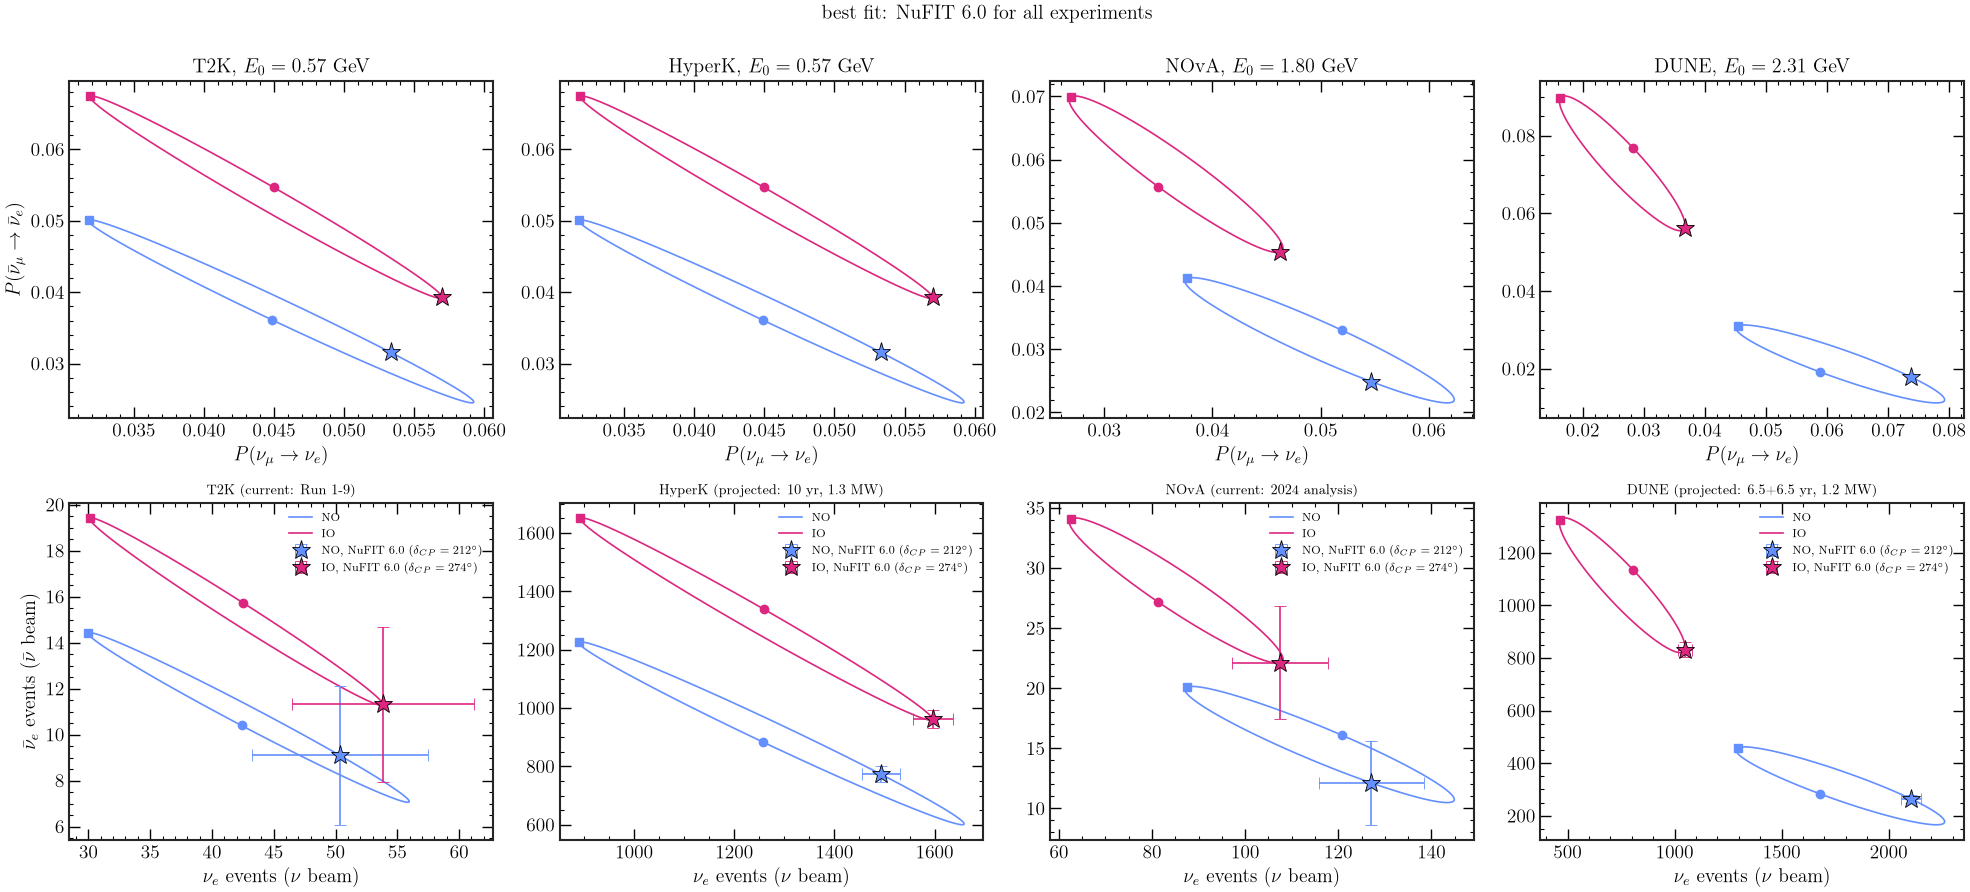

In [34]:
bi_plot("nufit")

**(b) T2K and NOvA at their own latest best fit, Hyper-K and DUNE at NuFIT 6.0**

T2K and NOvA prefer different values of $\delta_{CP}$ in NO ($235°$ vs $157°$): in the bi-event plane their best fits sit
on different sides of the ellipse, the well-known mild tension between the two experiments in normal ordering. In IO
both prefer $\delta_{CP}\approx 275$–$280°$.

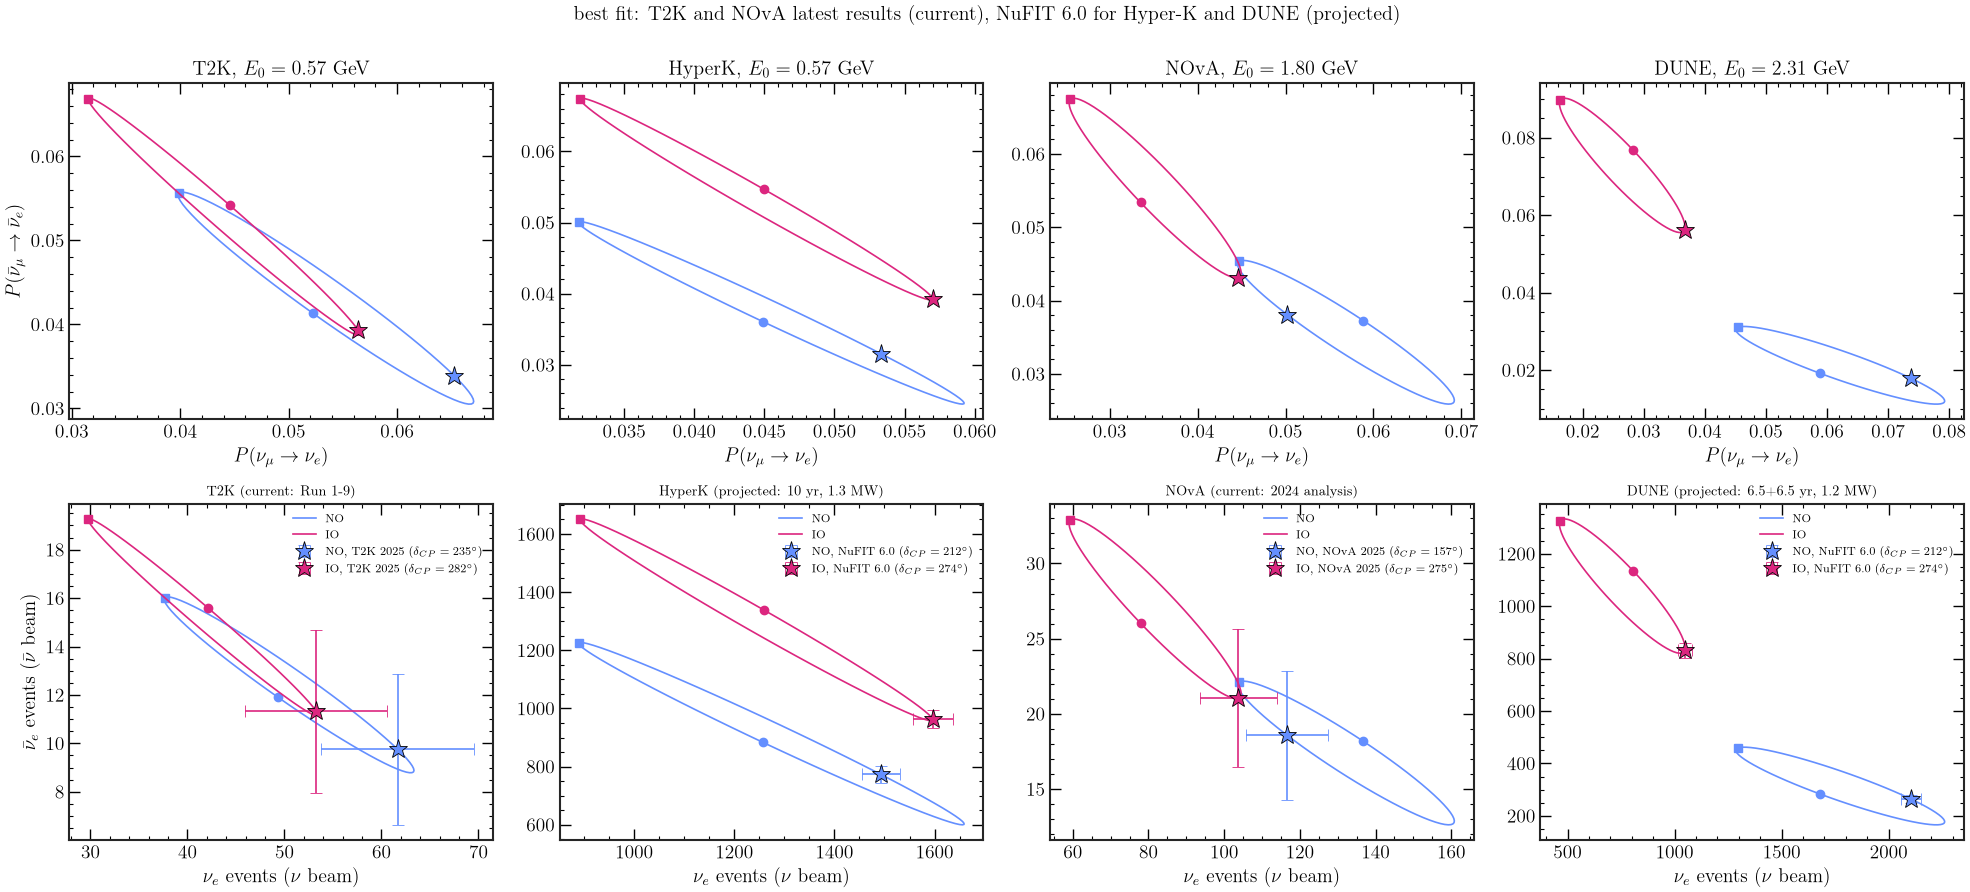

In [35]:
bi_plot("experiments")

### 5b. What each parameter does to the bi-probability plot

One experiment (DUNE baseline, $L = 1300$ km, $\rho = 2.848$ g/cm³, $E = 2.5$ GeV, close to the first oscillation
maximum). Each ellipse is a full $\delta_{CP}$ scan (circle: $\delta_{CP}=0$, square: $90°$); in each panel **one**
parameter is changed, all the others are at NuFIT 6.0 NO. The grey line is $P=\bar P$.

At the oscillation maximum the appearance probability is approximately (Cervera *et al.*, Nucl. Phys. B 579 (2000) 17)

$$
P(\nu_\mu\to\nu_e) \simeq \underbrace{\sin^2\theta_{23}\,\sin^22\theta_{13}\,\frac{\sin^2[(1-x)\Delta]}{(1-x)^2}}_{\text{"atmospheric"}}
+ \underbrace{\alpha\,J_0\,\frac{\sin(x\Delta)}{x}\frac{\sin[(1-x)\Delta]}{1-x}\,\cos(\Delta+\delta_{CP})}_{\text{interference}}
+ \mathcal O(\alpha^2),
$$

with $\Delta = \Delta m^2_{31}L/4E$, $x = A/\Delta m^2_{31}$ (matter), $\alpha = \Delta m^2_{21}/\Delta m^2_{31}$,
$J_0 = \sin2\theta_{12}\sin2\theta_{13}\sin2\theta_{23}\cos\theta_{13}$; for $\bar\nu$: $\delta_{CP}\to-\delta_{CP}$, $x\to -x$.
The atmospheric term sets **where** the ellipse is, the interference term (∝ $\cos\delta_{CP}$ and $\sin\delta_{CP}$) its **size and
shape**.

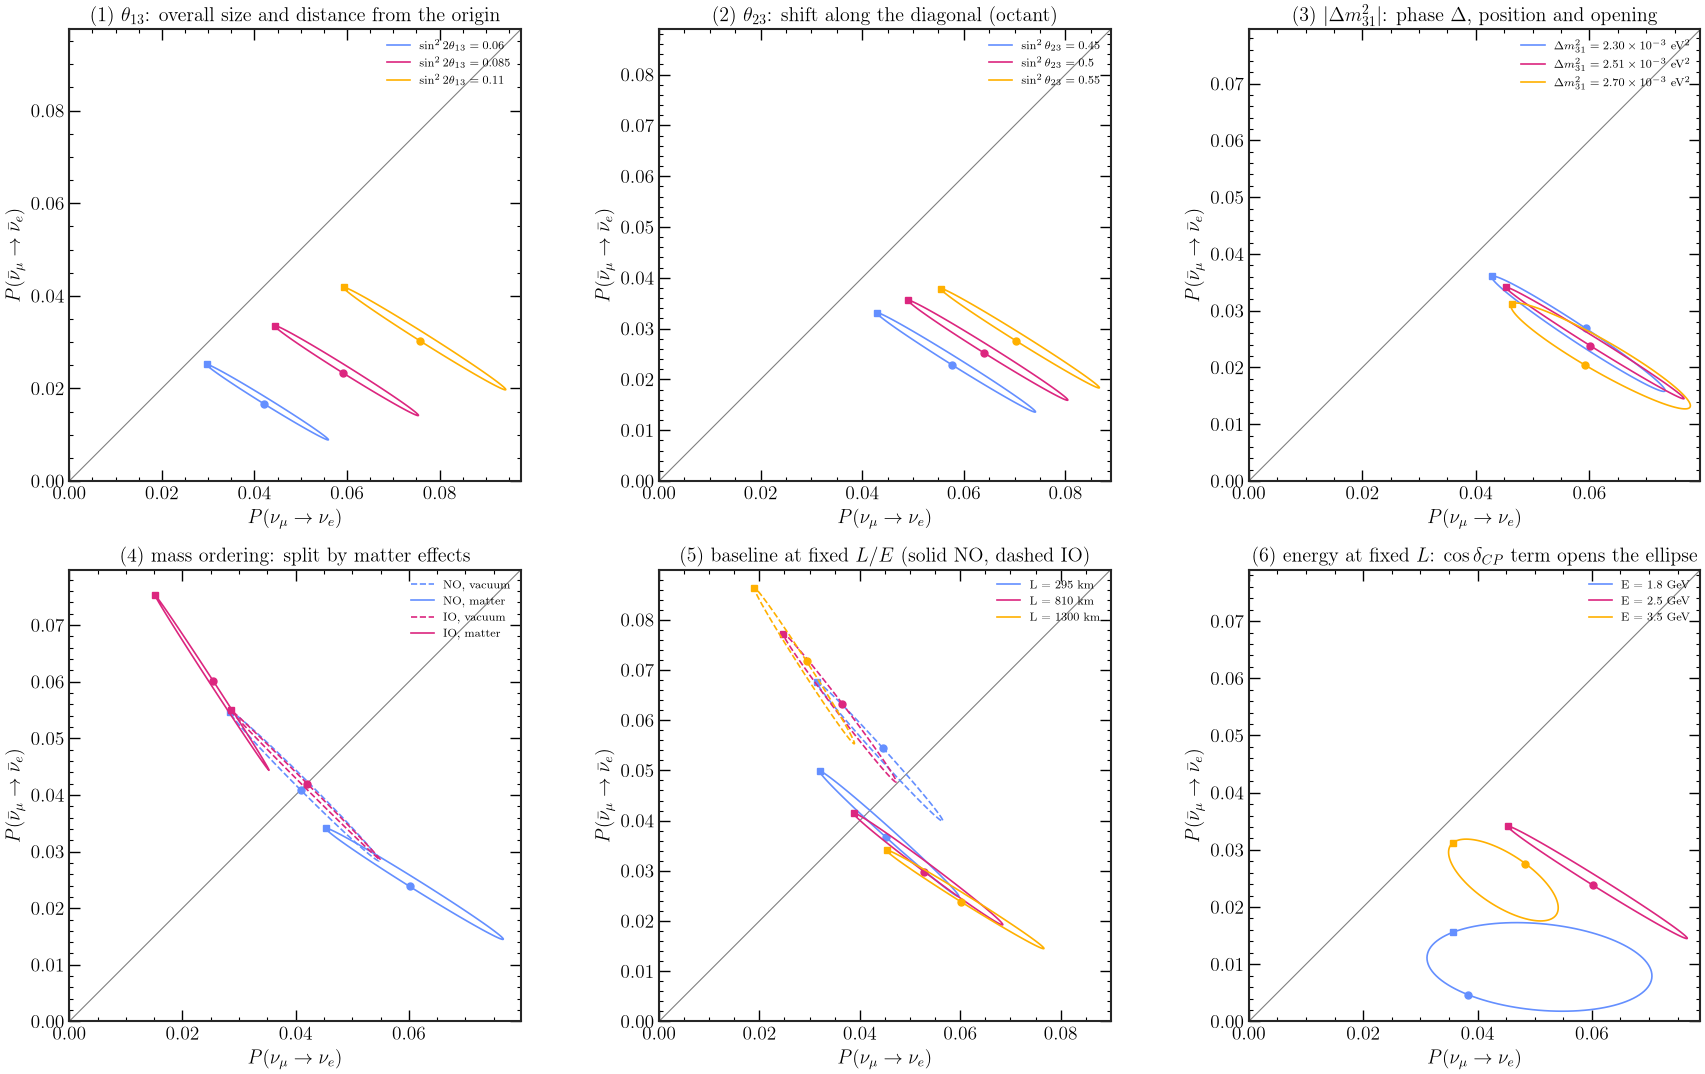

In [36]:
def ellipse(osc_kw, E=2.5, L=1300.0, rho=2.848, ordering="NO", deltas=np.arange(0, 361, 3)):
    # (P, Pbar) along a delta_CP scan
    out = []
    for d in deltas:
        kw = dict(osc_kw, delta_cp=d)
        nu = NeutrinoOscillator(ordering, baseline=L, rho=rho, **kw)
        nub = NeutrinoOscillator(ordering, baseline=L, rho=rho, antineutrino=True, **kw)
        out.append([float(nu.matter("mu", "e", E=E)), float(nub.matter("mu", "e", E=E))])
    return np.array(out), deltas

def draw(ax, Z, deltas, color, label, ls="-"):
    ax.plot(Z[:, 0], Z[:, 1], color=color, ls=ls, label=label)
    ax.plot(*Z[deltas == 0][0], "o", color=color, ms=5)
    ax.plot(*Z[deltas == 90][0], "s", color=color, ms=5)

def s13_from(s22):          # sin^2(theta13) from sin^2(2 theta13)
    return (1 - np.sqrt(1 - s22)) / 2

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
ax = axes.ravel()

# 1. theta_13
for i, s22 in enumerate([0.06, 0.085, 0.11]):
    Z, d = ellipse(dict(s2_13=s13_from(s22)))
    draw(ax[0], Z, d, c[i], rf"$\sin^2 2\theta_{{13}} = {s22}$")
ax[0].set_title(r"(1) $\theta_{13}$: overall size and distance from the origin")

# 2. theta_23 (octant)
for i, s23 in enumerate([0.45, 0.50, 0.55]):
    Z, d = ellipse(dict(s2_23=s23))
    draw(ax[1], Z, d, c[i], rf"$\sin^2\theta_{{23}} = {s23}$")
ax[1].set_title(r"(2) $\theta_{23}$: shift along the diagonal (octant)")

# 3. |dm2_31|: oscillation phase at fixed E
for i, dm in enumerate([2.3e-3, 2.513e-3, 2.7e-3]):
    Z, d = ellipse(dict(dm2_31=dm))
    draw(ax[2], Z, d, c[i], rf"$\Delta m^2_{{31}} = {dm * 1e3:.2f}\times10^{{-3}}$ eV$^2$")
ax[2].set_title(r"(3) $|\Delta m^2_{31}|$: phase $\Delta$, position and opening")

# 4. ordering and matter
nufit_no = NeutrinoOscillator("NO").params
same = {k: v for k, v in nufit_no.items() if k != "dm2_31"}          # same angles for NO and IO
for i, (o, dm) in enumerate((("NO", nufit_no["dm2_31"]), ("IO", -(nufit_no["dm2_31"] - 2 * nufit_no["dm2_21"])))):
    for rho, ls, lab in ((0.0, "--", "vacuum"), (2.848, "-", "matter")):
        Z, d = ellipse(dict(same, dm2_31=dm), ordering=o, rho=rho)
        draw(ax[3], Z, d, c[i], f"{o}, {lab}", ls=ls)
ax[3].set_title("(4) mass ordering: split by matter effects")

# 5. baseline (with E scaled so that L/E is fixed: same vacuum phase)
for i, L in enumerate([295.0, 810.0, 1300.0]):
    for j, o in enumerate(("NO", "IO")):
        Z, d = ellipse({}, E=2.5 * L / 1300.0, L=L, ordering=o)
        draw(ax[4], Z, d, c[i], f"L = {L:.0f} km" if j == 0 else None, ls="-" if o == "NO" else "--")
ax[4].set_title(r"(5) baseline at fixed $L/E$ (solid NO, dashed IO)")

# 6. energy at fixed L
for i, E in enumerate([1.8, 2.5, 3.5]):
    Z, d = ellipse({}, E=E)
    draw(ax[5], Z, d, c[i], f"E = {E} GeV")
ax[5].set_title(r"(6) energy at fixed $L$: $\cos\delta_{CP}$ term opens the ellipse")

for a in ax:
    lim = max(a.get_xlim()[1], a.get_ylim()[1])
    a.plot([0, lim], [0, lim], color="gray", lw=0.8, zorder=0)
    a.set_xlim(0, lim); a.set_ylim(0, lim)
    a.set_aspect("equal")
    a.set_xlabel(r"$P(\nu_\mu\to\nu_e)$")
    a.set_ylabel(r"$P(\bar\nu_\mu\to\bar\nu_e)$")
    a.legend(fontsize="x-small", loc="upper right")
plt.tight_layout()
plt.show()

**Reading the six panels**

1. **$\theta_{13}$** multiplies everything: the atmospheric term goes as $\sin^22\theta_{13}$, the interference term as
   $\sin2\theta_{13}$. The ellipse moves away from the origin along the diagonal and grows. Since reactors measure
   $\theta_{13}$ to ~3 %, this is a small effect in practice.
2. **$\theta_{23}$** enters the atmospheric term as $\sin^2\theta_{23}$ (different in the two octants) and the interference
   term as $\sin2\theta_{23}$ (the same for $\theta_{23}$ and $90°-\theta_{23}$): the ellipse slides along the diagonal with
   almost the same size. A shift along the diagonal can also come from $\delta_{CP}$ moving along the ellipse, which is the
   **octant–$\delta_{CP}$ degeneracy**.
3. **$|\Delta m^2_{31}|$** changes the phase $\Delta$ at fixed energy. Moving away from the maximum ($\Delta=\pi/2$) reduces the
   atmospheric term and turns part of the $\sin\delta_{CP}$ dependence into $\cos\delta_{CP}$: the ellipse moves and opens.
4. **Mass ordering.** With the same angles, in vacuum the NO and IO ellipses almost coincide. Matter enhances $\nu$ and
   suppresses $\bar\nu$ for NO (and the opposite for IO), pushing the two ellipses to opposite sides of the diagonal:
   the separation **perpendicular** to the diagonal measures the ordering, the position **along** each ellipse measures
   $\delta_{CP}$.
5. **Baseline at fixed $L/E$:** the vacuum part is the same, only the matter effect changes. At 295 km (T2K, Hyper-K)
   the NO and IO ellipses overlap, so $\delta_{CP}$ and the ordering are degenerate; at 1300 km (DUNE) they are separate.
6. **Energy at fixed $L$:** at the maximum the ellipse is almost a line along the anti-diagonal (pure $\sin\delta_{CP}$:
   $\nu$ up, $\bar\nu$ down); above or below it the $\cos\delta_{CP}$ term opens the ellipse. Using more than one energy
   (the energy spectrum) breaks degeneracies that a single point cannot.

## 6. $\delta_{CP}$ sensitivity

How well can each experiment exclude **CP conservation** ($\delta_{CP} = 0$ or $180°$) if the true value is $\delta_{CP}$?
With two numbers ($N_\nu$, $N_{\bar\nu}$) and Poisson errors,

$$
\Delta\chi^2(\delta_{CP}^\text{true}) = \min_{\delta_{CP}^\text{test}\in\{0,\,180°\}}\;\sum_{\nu,\bar\nu}
\frac{\left[N(\delta_{CP}^\text{true}) - N(\delta_{CP}^\text{test})\right]^2}{N(\delta_{CP}^\text{true}) + \left(f\,N(\delta_{CP}^\text{true})\right)^2},
$$

and the significance is $\sqrt{\Delta\chi^2}$. $f$ is a fractional normalisation uncertainty on each sample:
**top row** statistics only ($f=0$), **bottom row** $f = 5\%$ (`SYSTS`).

* **Solid:** the mass ordering is known (the test points have the true ordering).
* **Dashed:** the ordering is unknown (the minimum is also taken over the CP-conserving points of the other ordering,
  with its NuFIT parameters).

T2K     true NO, f = 0.00: max   2.5 sigma, delta range with > 3 sigma:    0 %
T2K     true NO, f = 0.05: max   2.4 sigma, delta range with > 3 sigma:    0 %
T2K     true IO, f = 0.00: max   2.3 sigma, delta range with > 3 sigma:    0 %
T2K     true IO, f = 0.05: max   2.2 sigma, delta range with > 3 sigma:    0 %
HyperK  true NO, f = 0.00: max  15.7 sigma, delta range with > 3 sigma:   87 %
HyperK  true NO, f = 0.05: max   8.5 sigma, delta range with > 3 sigma:   73 %
HyperK  true IO, f = 0.00: max  14.5 sigma, delta range with > 3 sigma:   85 %
HyperK  true IO, f = 0.05: max   7.5 sigma, delta range with > 3 sigma:   70 %
NOvA    true NO, f = 0.00: max   2.9 sigma, delta range with > 3 sigma:    0 %
NOvA    true NO, f = 0.05: max   2.6 sigma, delta range with > 3 sigma:    0 %
NOvA    true IO, f = 0.00: max   2.7 sigma, delta range with > 3 sigma:    0 %
NOvA    true IO, f = 0.05: max   2.5 sigma, delta range with > 3 sigma:    0 %
DUNE    true NO, f = 0.00: max  14.9 sigma, delta ra

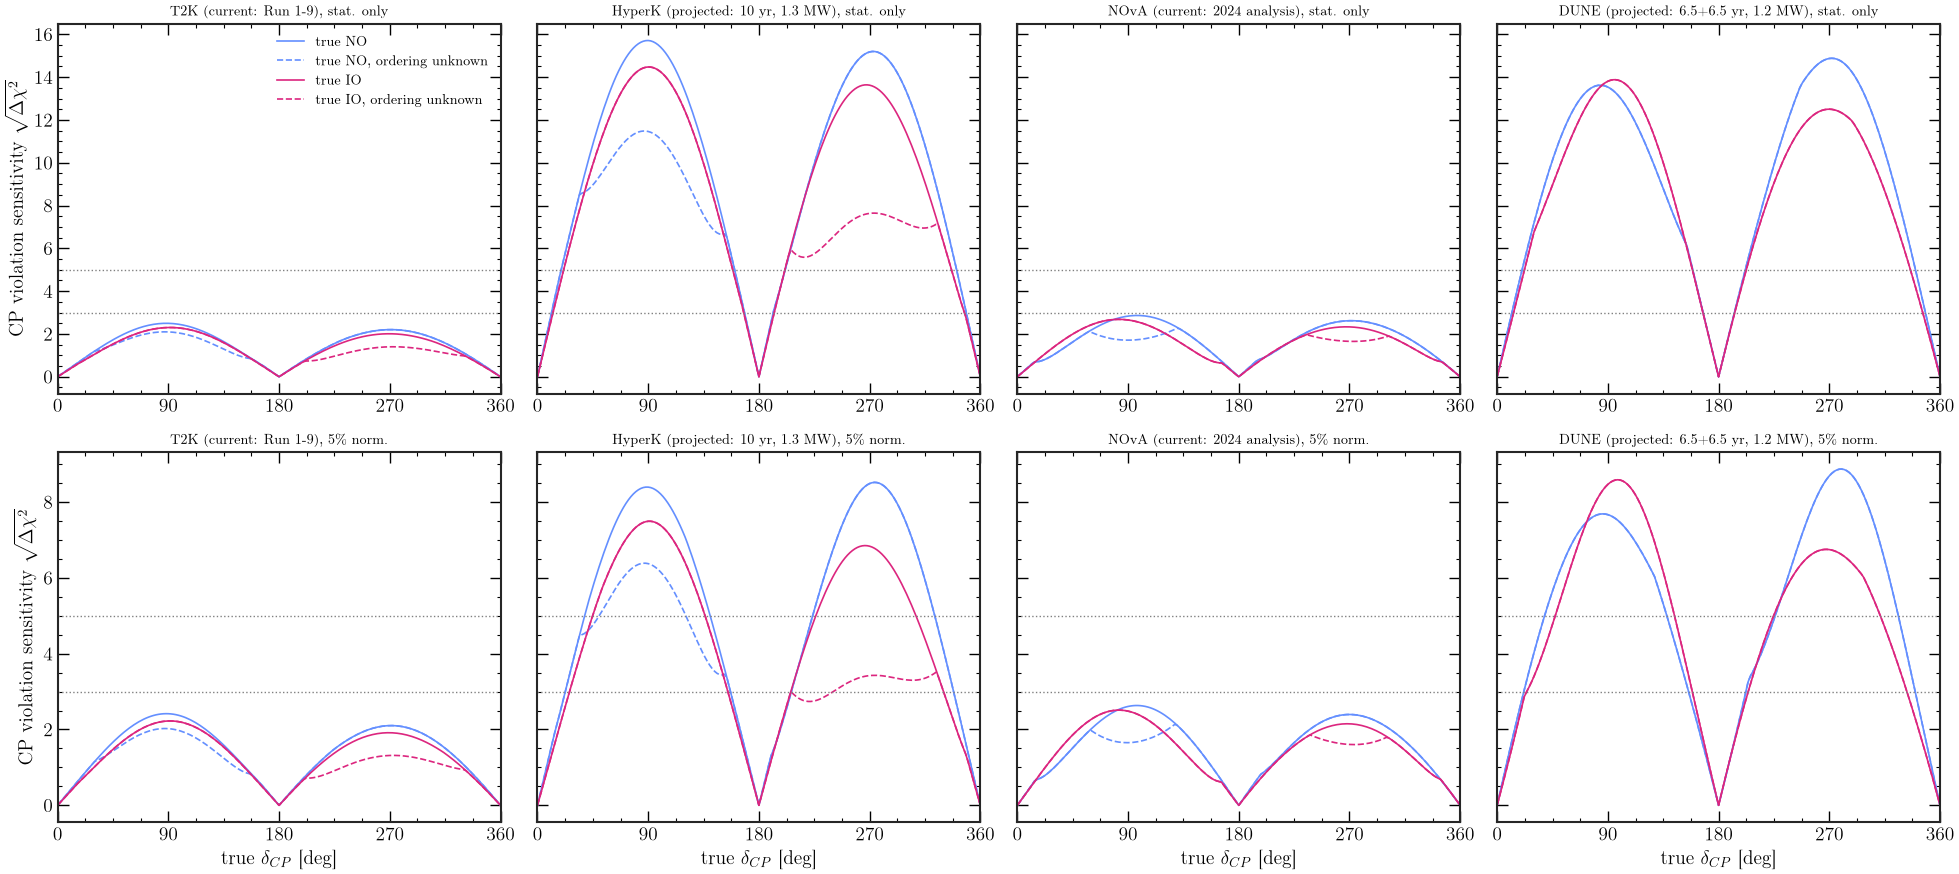

In [37]:
SYSTS = [0.0, 0.05]   # fractional normalisation uncertainty f: statistics only (top) and 5 % (bottom)
d_true = np.arange(0, 361, 2)

def counts(name, o, d):
    return np.array([n_events(name, m, ordering=o, delta_cp=d) for m in MODES])

fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharey="row")
for j, name in enumerate(EXPERIMENTS):
    cp = {o: [counts(name, o, d) for d in (0, 180)] for o in ("NO", "IO")}   # CP-conserving test points
    for i, o in enumerate(("NO", "IO")):
        other = "IO" if o == "NO" else "NO"
        Nt_all = [counts(name, o, d) for d in d_true]
        for row, SYST in enumerate(SYSTS):
            ax = axes[row, j]
            s_known, s_unknown = [], []
            for Nt in Nt_all:
                var = Nt + (SYST * Nt) ** 2
                chi = lambda Ntest: np.sum((Nt - Ntest) ** 2 / var)
                known = min(chi(N0) for N0 in cp[o])
                s_known.append(np.sqrt(known))
                s_unknown.append(np.sqrt(min(known, min(chi(N0) for N0 in cp[other]))))
            s_known = np.array(s_known)
            ax.plot(d_true, s_known, color=c[i], label=f"true {o}")
            ax.plot(d_true, s_unknown, color=c[i], ls="--", label=f"true {o}, ordering unknown")
            print(f"{name:7s} true {o}, f = {SYST:.2f}: max {s_known.max():5.1f} sigma, "
                  f"delta range with > 3 sigma: {np.mean(s_known > 3) * 100:4.0f} %")
    for row, SYST in enumerate(SYSTS):
        ax = axes[row, j]
        for z in (3, 5):
            ax.axhline(z, color="gray", ls=":", lw=1)
        ax.set_xticks([0, 90, 180, 270, 360])
        ax.set_xlim(0, 360)
        ax.set_title(f"{name} ({SETUP[name]['status']}), " + ("stat. only" if SYST == 0 else f"{100 * SYST:.0f}" + (r"\%" if plt.rcParams["text.usetex"] else "%") + " norm."),
                     fontsize="small")
    axes[1, j].set_xlabel(r"true $\delta_{CP}$ [deg]")
for row in range(2):
    axes[row, 0].set_ylabel(r"CP violation sensitivity $\sqrt{\Delta\chi^2}$")
axes[0, 0].legend(fontsize="small")
plt.tight_layout()
plt.show()

**What we learn**

* The bi-probability ellipses and the bi-event ellipses have the same shape: in this model events are just
  probabilities times a constant. The constant (exposure × cross section × flux) sets the size of the error bars.
* $\delta_{CP}$ moves the point **along** an ellipse (mostly $\sin\delta_{CP}$: $\nu$ up and $\bar\nu$ down, or the reverse);
  the ordering moves the whole ellipse (matter effect). At T2K/Hyper-K (295 km) the NO and IO ellipses are close
  (and part of their distance comes from the different NuFIT $\theta_{23}$ of the two orderings), at DUNE (1300 km)
  they are far apart.
* With today's exposures T2K and NOvA reach only about 2–3σ even for the most favourable $\delta_{CP}$;
  Hyper-K and DUNE exceed 5σ for a large part of the $\delta_{CP}$ range. The sensitivity always vanishes at
  $0$ and $180°$.
* **Systematics matter for the big experiments.** Statistics only, Hyper-K and DUNE reach ~15σ; a 5 % normalisation
  uncertainty brings them to ~8σ, close to the published projections. For T2K and NOvA (statistics-limited) the
  5 % changes almost nothing.
* **Ordering unknown (dashed):** for the short baseline the CP-violating point of one ordering can look like a
  CP-conserving point of the other, and the sensitivity drops in part of the $\delta_{CP}$ range. DUNE resolves the
  ordering by itself, so its dashed and solid curves almost coincide.
* These numbers are still **optimistic**: no backgrounds (they add ~15–40 % events with no $\delta_{CP}$ information),
  no energy information, a single normalisation systematic. The pattern (where in $\delta_{CP}$, which experiment,
  role of the ordering and of systematics) is the same as in the full analyses.